# Estadificación del sueño con DART y CRNN

Clasificación retrospectiva de épocas de 30 segundos en Sleep-Telemetry y Sleep-Cassette. La evaluación reserva personas completas de ambas cohortes. La combinación utiliza un LightGBM DART y una CRNN espectral contextual; ambos predicen las mismas cinco etapas. El ajuste final con el 100 % se exporta después del informe de prueba.

### Hiperparámetros de LightGBM

DART usa **667 iteraciones** con una tasa de aprendizaje de **0,03**. Cada árbol tiene hasta **36 hojas**, profundidad máxima **8** y un mínimo de **25 segmentos por hoja**.

| Parámetro | Valor del modelo |
| --- | --- |
| Muestreo por iteración | 80 % de los segmentos y 60 % de las características |
| Regularización | L1 = 0,1, L2 = 1,5 |
| Descarte de árboles en DART | `drop_rate` = 0,1, `skip_drop` = 0,5 |
| Pesos por etapa | N1 = 2,2, N2 = 0,41, N3 = 1,56, REM = 1,0, W = 2,01 |
| Semilla | 42 |

### Arquitectura de la CRNN contextual

La red procesa **15 segmentos consecutivos de 30 segundos** (7,5 minutos). La convolución identifica patrones dentro de cada segmento y la GRU bidireccional usa los segmentos anteriores y posteriores de la ventana para estimar la etapa de sueño.

| Capa | Configuración y función |
| --- | --- |
| Entrada | 15 segmentos × 6 bloques de 5 s × 96 características. Las características combinan la potencia por banda de los dos EEG, el EOG y el EMG con su normalización y su contexto temporal. |
| Convolución por segmento | Conv1D con 48 filtros de ancho 3 y activación ReLU. Recorre los seis bloques y conserva una salida por bloque. |
| Resumen del segmento | Se aplanan las 6 × 48 salidas y una capa densa con ReLU las reduce a 48 valores. Dropout del 15 %. |
| Contexto entre segmentos | GRU bidireccional con 32 unidades por dirección. Las dos direcciones aportan 64 valores por segmento. Dropout del 20 %. |
| Salida | Una capa densa con softmax produce cinco probabilidades por segmento, una para cada etapa (N1, N2, N3, REM y W). |

**Entrenamiento.** Adam con tasa de aprendizaje 0,001, 15 épocas, lotes de 64 secuencias y semilla 42. En inferencia se combinan tres ventanas solapadas mediante una media geométrica. La distribución resultante aporta el 30 % de la mezcla final con DART en escala logarítmica.

In [1]:
import hashlib
import json
import os
import sys
import tempfile
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
from uuid import uuid4

os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '5')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')

import lightgbm as lgb
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.fft import rfft
from scipy.ndimage import convolve1d
from scipy.special import softmax
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data.dvc').is_file())
SRC = ROOT / 'packages/sleep-staging/src'
sys.path.insert(0, str(SRC))
from sleep_staging import PreprocessingConfig, PreprocessingPipeline
from sleep_staging.datasets import discover_sleep_cassette_records, discover_sleep_telemetry_records
from sleep_staging.training import create_lightgbm_classifier, load_or_build_supervised_dataset

DATA = ROOT / 'data'
STORE = DATA / 'models/dart_crnn_mixto'
SPEC = json.loads((DATA / 'experimentos/lightgbm_st_sc/experimento.json').read_text('utf8'))
CLASES = np.array(SPEC['classes'])
COLUMNAS = SPEC['feature_columns']
PERFILES = {c: SPEC['preprocessing_' + c.lower()] for c in ('Telemetry', 'Cassette')}
CANALES = PERFILES['Telemetry']['channels']
PARAMS = dict(SPEC['parameters'], n_jobs=6)
BANDAS = [(0.3, 4), (4, 8), (8, 12), (12, 16), (16, 30), (30, 35)]
DESFASES = (0, 5, 10)
SEMILLA = 42
tf.config.experimental.enable_op_determinism()

## Datos y partición por persona

Se conserva el primer grupo de prueba de la comparación previa para evaluar los modelos sobre las mismas noches. La estratificación es por cohorte y la semilla es 42. Este conjunto ya se utilizó en el desarrollo experimental.

In [2]:
registros = {'Telemetry': discover_sleep_telemetry_records(DATA/'sleep-telemetry'),
             'Cassette': discover_sleep_cassette_records(DATA/'sleep-cassette')}
indices, tablas = [], []
for cohorte, lista in registros.items():
    pipeline = PreprocessingPipeline(PreprocessingConfig(**PERFILES[cohorte]))
    grupos = [lista] if cohorte == 'Telemetry' else [[r] for r in lista]
    cache = DATA/'processed/supervised' if cohorte == 'Telemetry' else Path(tempfile.gettempdir())/'sleep-edfx-sc-features-v1'
    for grupo in grupos:
        ds = load_or_build_supervised_dataset(grupo, pipeline, cache, verbose=False)
        tablas.append(ds.features.reindex(columns=COLUMNAS).astype('float32'))
        indices.append(ds.metadata[['record_id','subject_id','epoch_index']].assign(cohorte=cohorte, etapa=ds.labels.to_numpy()))
X = pd.concat(tablas, ignore_index=True)
meta = pd.concat(indices, ignore_index=True)
del tablas, indices, ds
assert len(meta)==len(X) and not meta.duplicated(['record_id','epoch_index']).any()
assert sorted(meta.etapa.unique())==CLASES.tolist()
personas = meta[['cohorte','subject_id']].drop_duplicates().sort_values(['cohorte','subject_id'])
assert personas.subject_id.is_unique
_, idx_test = next(StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(personas, personas.cohorte))
prueba = meta.subject_id.isin(personas.iloc[idx_test].subject_id)
train, test = meta[~prueba], meta[prueba]
assert set(train.subject_id).isdisjoint(test.subject_id)
resumen = meta.assign(particion=np.where(prueba,'Prueba','Entrenamiento')).groupby(['particion','cohorte']).agg(
    personas=('subject_id','nunique'), noches=('record_id','nunique'), segmentos=('etapa','size'))
display(resumen)
display(test.groupby('cohorte').agg(personas=('subject_id',lambda x: ', '.join(sorted(set(x)))),
                                    registros=('record_id',lambda x: ', '.join(sorted(set(x))))))

personas  noches  segmentos
particion     cohorte                               
Entrenamiento Cassette          9       9      24882
              Telemetry        18      36      34837
Prueba        Cassette          3       3       8039
              Telemetry         4       8       7854

,personas,registros
cohorte,,
Cassette,"SC410, SC434, SC435","SC4101, SC4342, SC4352"
Telemetry,"S05, S14, S21, S22","ST7051, ST7052, ST7141, ST7142, ST7211, ST7212..."


## DART

El paquete del proyecto prepara las características tabulares y construye el clasificador. La configuración mixta conserva el orden de sus 2.280 columnas y sus pesos por etapa. Las características de EMG no disponibles en Cassette se representan como valores ausentes.

In [3]:
def entrenar_dart(filas):
    modelo = create_lightgbm_classifier(**PARAMS)
    modelo.fit(X.loc[filas.index], filas.etapa)
    np.testing.assert_array_equal(modelo.classes_, CLASES)
    return modelo.booster_

## CRNN contextual

La rama neuronal usa dos EEG, EOG y EMG. Después del filtro de 0,3–35 Hz y la normalización por época, cada segmento produce seis bloques de cinco segundos y seis bandas por canal. Se añaden la escala robusta de la noche y dos ventanas de contexto (7,5 y 2 minutos). La red combina convolución y GRU bidireccional sobre secuencias de 15 épocas. Las etiquetas de relleno y las épocas sin anotación se excluyen de la pérdida.

In [4]:
def entrada_crnn(archivo_edf):
    with mne.io.read_raw_edf(archivo_edf, preload=True, verbose='ERROR') as raw:
        if raw.info['sfreq'] != 100:
            raise ValueError('La CRNN requiere una señal a 100 Hz.')
        presentes = [c for c in CANALES if c in raw.ch_names]
        if not set(CANALES[:3]).issubset(presentes):
            raise ValueError(f'Faltan señales EEG/EOG en {archivo_edf.name}')
        raw.pick(presentes).filter(.3, 35., verbose=False)
        n = raw.n_times // 3000
        signal = np.zeros((n, 3000, 4), dtype='float32')
        for j, ch in enumerate(CANALES):
            if ch in presentes:
                v = raw.get_data(picks=[ch], stop=n*3000).reshape(n, 3000)*1e6
                signal[:,:,j] = (v-v.mean(1,keepdims=True))/(v.std(1,keepdims=True)+1e-8)
    f = np.fft.rfftfreq(500, 1/100)
    ventana = np.hanning(500).astype('float32')[None,None,:,None]
    x = np.empty((n, 6, 24), dtype='float32')
    for i in range(0,n,100):
        bloque = signal[i:i+100].reshape(-1,6,500,4)
        potencia = np.abs(rfft(bloque*ventana, axis=2))**2/500
        x[i:i+len(bloque)] = np.concatenate([
            np.log1p(potencia[:,:,(f>=a)&(f<b)].mean(axis=2)) for a,b in BANDAS], axis=-1)
    q10, mediana, q90 = np.percentile(x.reshape(-1,24), [10,50,90], axis=0)
    z = np.clip((x-mediana)/np.maximum(q90-q10,.05),-5,5).astype('float32')
    media = z.mean(axis=1)
    triangular = np.r_[1:9,7:0:-1].astype('float32')
    centro = convolve1d(media, triangular/triangular.sum(), axis=0, mode='nearest')
    pad = np.pad(media,((3,0),(0,0)),mode='edge')
    pasado = sum(pad[i:i+n] for i in range(4))/4
    return np.concatenate([x,z,np.broadcast_to(centro[:,None],x.shape),
                           np.broadcast_to(pasado[:,None],x.shape)],axis=-1)

def bloques(x, desfase, relleno=0):
    pad = [(desfase,-(len(x)+desfase)%15)] + [(0,0)]*(x.ndim-1)
    return np.pad(x,pad,constant_values=relleno).reshape(-1,15,*x.shape[1:])

In [5]:
def entrenar_crnn(filas, entradas):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    rng = np.random.default_rng(SEMILLA)
    l = tf.keras.layers
    entrada = l.Input((15,6,96))
    z = l.TimeDistributed(l.Conv1D(48,3,padding='same',activation='relu'))(entrada)
    z = l.TimeDistributed(l.Flatten())(z)
    z = l.Dropout(.15)(l.Dense(48,activation='relu')(z))
    z = l.Bidirectional(l.GRU(32,return_sequences=True))(z)
    red = tf.keras.Model(entrada,l.Dense(5,activation='softmax')(l.Dropout(.20)(z)))
    red.compile(optimizer=tf.keras.optimizers.Adam(.001), loss='sparse_categorical_crossentropy')
    conteos = filas.etapa.value_counts().reindex(CLASES).to_numpy()
    pesos = (conteos.mean()/conteos)**.35
    pesos /= np.average(pesos,weights=conteos)
    lotes = {}
    for d in DESFASES:
        xs, ys = [], []
        for rid,g in filas.groupby('record_id'):
            y = np.full(len(entradas[rid]),-1,dtype='int32')
            y[g.epoch_index] = pd.Categorical(g.etapa,categories=CLASES).codes
            y = bloques(y,d,-1)
            valido = (y>=0).any(1)
            xs.append(bloques(entradas[rid],d)[valido])
            ys.append(y[valido])
        x,y = np.concatenate(xs),np.concatenate(ys)
        lotes[d] = (x,y.clip(0),np.where(y>=0,pesos[y.clip(0)],0).astype('float32'))
    for epoca in range(15):
        x,y,w = lotes[DESFASES[epoca%3]]
        orden = rng.permutation(len(x))
        red.fit(x[orden], y[orden], sample_weight=w[orden], batch_size=64, epochs=1, shuffle=False, verbose=0)
    return red

def prob_crnn(red,x):
    vistas = []
    for d in DESFASES:
        v = red.predict(bloques(x,d),batch_size=128,verbose=0).reshape(-1,len(CLASES))
        vistas.append(v[d:d+len(x)].astype('float64'))
    return softmax(np.log(np.maximum(vistas,1e-10)).mean(axis=0),axis=1)

## Fusión y persistencia

La media geométrica ponderada asigna un 70 % a DART y un 30 % a la CRNN. Cada fila conserva el orden N1, N2, N3, REM y W. La etapa estimada es la de mayor probabilidad conjunta. Las dos instantáneas de modelos tienen manifiestos independientes, con las personas de entrenamiento, procedencia de las entradas, pesos, orden de clases y sumas de verificación.

In [6]:
def combinar(p_dart, p_crnn):
    if p_dart.shape != p_crnn.shape:
        raise ValueError('Las probabilidades de ambas ramas deben estar alineadas.')
    return softmax(.70*np.log(np.maximum(p_dart,1e-7)) + .30*np.log(np.maximum(p_crnn,1e-7)), axis=1)

def sha256(path):
    with path.open('rb') as f:
        return hashlib.file_digest(f,'sha256').hexdigest() if hasattr(hashlib,'file_digest') else digest_stream(f)

def digest_stream(f):
    h = hashlib.sha256()
    for chunk in iter(lambda: f.read(2**20), b''):
        h.update(chunk)
    return h.hexdigest()

registros_planos = [r for lista in registros.values() for r in lista]
huellas = {r.record_id: {'persona':r.subject_id,'psg':sha256(r.psg_path),'hipnograma':sha256(r.hypnogram_path)}
           for r in registros_planos}
entradas = {r.record_id: entrada_crnn(r.psg_path) for r in registros_planos}

In [7]:
def huella_json(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

codigo = json.loads((ROOT/'Notebooks/dart_crnn_mixto.ipynb').read_text('utf8'))['cells']
receta = huella_json({c['id']:c['source'] for c in codigo if c['id'] in ('setup','datos','dart','espectro','crnn','fusion')})
paquete = huella_json({p.relative_to(SRC).as_posix():hashlib.sha256(p.read_bytes().replace(b'\r\n',b'\n')).hexdigest() for p in sorted((SRC/'sleep_staging').rglob('*.py'))})
versiones = {p:version(p) for p in ('lightgbm','tensorflow','keras','mne','numpy','scipy','scikit-learn','pandas')}

prepro_crnn = {'alcance': 'Una noche completa. Salida por época de 30 s desde el inicio del EDF. Muestras finales incompletas descartadas.',
 'frecuencia_hz': 100,
 'duracion_epoca_s': 30,
 'segmento_espectral_s': 5,
 'filtro': {'tipo': 'MNE FIR por canal', 'fmin_hz': 0.3, 'fmax_hz': 35, 'fase': 'zero', 'diseno': 'firwin'},
 'normalizacion_epoca': 'Convertir a microvoltios; restar media y dividir por desviación poblacional + 1e-8 por canal y época.',
 'canales_ausentes': 'EMG ausente se rellena con ceros después de normalizar. Se requieren ambos EEG y EOG.',
 'espectro': 'Hann simétrica 500 muestras, rFFT, potencia = abs(FFT)^2 / 500. Para cada banda [a,b), log1p(media de potencia). Orden '
             'banda, luego canal.',
 'contexto': 'Concatenar 24 valores originales, 24 robustos por noche, 24 medias centradas y 24 medias del pasado.',
 'escala_robusta': 'Mediana y percentiles 10 y 90 de todos los bloques de 5 s de la noche. Denominador máximo entre P90-P10 y 0,05. '
                   'Recorte [-5,5].',
 'ventana_centrada': 'Media de 6 bloques por época, luego 15 épocas con pesos triangulares 1..8..1; extender extremos replicando la '
                     'época del borde.',
 'ventana_pasada': 'Media de la época actual y las tres anteriores de las medias robustas por época, con replicación al inicio.',
 'secuencias': '15 épocas con padding de ceros al inicio según desfase y hasta completar el último bloque. Agregación por noche.',
 'agregacion': 'Media geométrica normalizada entre las tres posiciones de cada época, piso 1e-10 por probabilidad de vista.'}

def contrato(filas):
    return {'receta':receta, 'paquete':paquete, 'versiones':versiones,
            'registros_entrenamiento':{r:huellas[r] for r in sorted(filas.record_id.unique())},
            'personas_entrenamiento':sorted(filas.subject_id.unique()),'segmentos_entrenamiento':len(filas),
            'clases':CLASES.tolist(),'columnas_dart':COLUMNAS,'parametros_dart':PARAMS,
            'preprocesamiento_crnn':prepro_crnn, 'preprocesamiento_dart':PERFILES, 'canales_crnn':CANALES, 'bandas_hz':BANDAS,
            'entrada_crnn':[15,6,96],'desfases':DESFASES, 'fusion':{'tipo':'geometrica','dart':.70,'crnn':.30,'piso':1e-7}}

def cargar(manifiesto):
    info = json.loads(manifiesto.read_text('utf8'))
    rutas = {k:manifiesto.parent/v['nombre'] for k,v in info['archivos'].items()}
    if any(sha256(rutas[k])!=v['sha256'] for k,v in info['archivos'].items()):
        raise ValueError('La integridad de los pesos no coincide con el manifiesto.')
    return lgb.Booster(model_file=str(rutas['dart'])),tf.keras.models.load_model(rutas['crnn'],compile=False),info

def guardar(nombre, filas, dart, red, origen, segundos):
    carpeta = STORE/nombre
    carpeta.mkdir(parents=True,exist_ok=True)
    archivos = {}
    for rama,ext in [('dart','.txt'),('crnn','.keras')]:
        temporal = carpeta/(uuid4().hex+ext)
        if rama=='dart':
            dart.save_model(str(temporal))
        else:
            red.save(temporal)
        checksum = sha256(temporal)
        ruta = carpeta/(rama+'-'+checksum[:16]+ext)
        temporal.replace(ruta)
        archivos[rama] = {'nombre':ruta.name,'sha256':checksum}
    spec = contrato(filas)
    info = dict(contrato=spec,firma=huella_json(spec),archivos=archivos,origen=origen,tiempos_s=segundos)
    temporal = carpeta/(uuid4().hex+'.tmp')
    temporal.write_text(json.dumps(info,ensure_ascii=False,indent=2),encoding='utf8')
    temporal.replace(carpeta/'manifest.json')

def ajustar_o_cargar(nombre, filas):
    destino = STORE/nombre/'manifest.json'
    if destino.exists() and json.loads(destino.read_text('utf8'))['firma']==huella_json(contrato(filas)):
        print('Recuperado de DVC data:',nombre)
        return cargar(destino)
    inicio = perf_counter()
    dart = entrenar_dart(filas)
    intermedio = perf_counter()
    red = entrenar_crnn(filas,entradas)
    segundos = {'dart':intermedio-inicio,'crnn':perf_counter()-intermedio}
    guardar(nombre,filas,dart,red,'Ajuste con las personas del manifiesto',segundos)
    print('Ajustado y guardado:',nombre,{k:round(v,1) for k,v in segundos.items()})
    return cargar(destino)

## Evaluación sobre el 20 % reservado

El **resumen global** reúne las 11 noches de prueba de Telemetry y Cassette. El F1 macro es el promedio de los cinco F1 por etapa, con igual peso para cada una. La exactitud (*accuracy*) es la proporción de segmentos clasificados correctamente y el kappa de Cohen mide el acuerdo ajustado por azar. Debajo se muestra el desglose por cohorte y las matrices de confusión.

In [8]:
dart_eval, crnn_eval, ficha_eval = ajustar_o_cargar('evaluacion_80_20',train)
p_dart = dart_eval.predict(X.loc[test.index],num_threads=4)
p_crnn = np.empty_like(p_dart)
for rid,g in test.groupby('record_id'):
    p_crnn[test.index.get_indexer(g.index)] = prob_crnn(crnn_eval,entradas[rid])[g.epoch_index]
p_fusion = combinar(p_dart,p_crnn)
resultados = test.copy()
modelos = ['DART','CRNN','DART + CRNN']
for modelo, p in zip(modelos,[p_dart,p_crnn,p_fusion]):
    np.testing.assert_allclose(p.sum(axis=1),1,atol=1e-6)
    resultados[modelo] = CLASES[p.argmax(axis=1)]
def metricas(g):
    return pd.DataFrame([[f1_score(g.etapa,g[m],labels=CLASES,average='macro',zero_division=0),
                          accuracy_score(g.etapa,g[m]),cohen_kappa_score(g.etapa,g[m])] for m in modelos],
                        index=modelos,columns=['F1 macro','Exactitud','Kappa'])
globales = metricas(resultados).rename(columns={'Exactitud':'Exactitud (accuracy)', 'Kappa':'Kappa de Cohen'}).T
f1_etapas = pd.DataFrame(
    {m: f1_score(resultados.etapa, resultados[m], labels=CLASES, average=None, zero_division=0) for m in modelos},
    index=[f'F1 {etapa}' for etapa in CLASES],
)
resumen_prueba = pd.concat([globales, f1_etapas]).rename_axis('Métrica')
print(f'Resumen global · {len(resultados):,} segmentos de prueba'.replace(',', '.'))
display(resumen_prueba.style.format('{:.2%}').format('{:.4f}', subset=pd.IndexSlice[['Kappa de Cohen'], :]))
print('Resultados por cohorte')
display(pd.concat({k:metricas(g) for k,g in resultados.groupby('cohorte')}, names=['Cohorte','Modelo']).round(5))

Recuperado de DVC data: evaluacion_80_20


Resumen global · 15.893 segmentos de prueba


,DART,CRNN,DART + CRNN
Métrica,,,
F1 macro,81.94%,80.43%,83.48%
Exactitud (accuracy),87.45%,85.85%,88.74%
Kappa de Cohen,0.8262,0.8026,0.8435
F1 N1,63.73%,61.23%,65.55%
F1 N2,83.20%,84.21%,85.54%
F1 N3,78.87%,77.98%,80.24%
F1 REM,86.31%,84.13%,88.24%
F1 W,97.57%,94.57%,97.81%


Resultados por cohorte


F1 macro  Exactitud    Kappa
Cohorte   Modelo                                   
Cassette  DART          0.73936    0.91666  0.82957
          CRNN          0.70577    0.88518  0.77219
          DART + CRNN   0.75769    0.92711  0.85077
Telemetry DART          0.82624    0.83130  0.77236
          CRNN          0.81054    0.83117  0.76819
          DART + CRNN   0.83909    0.84670  0.79187

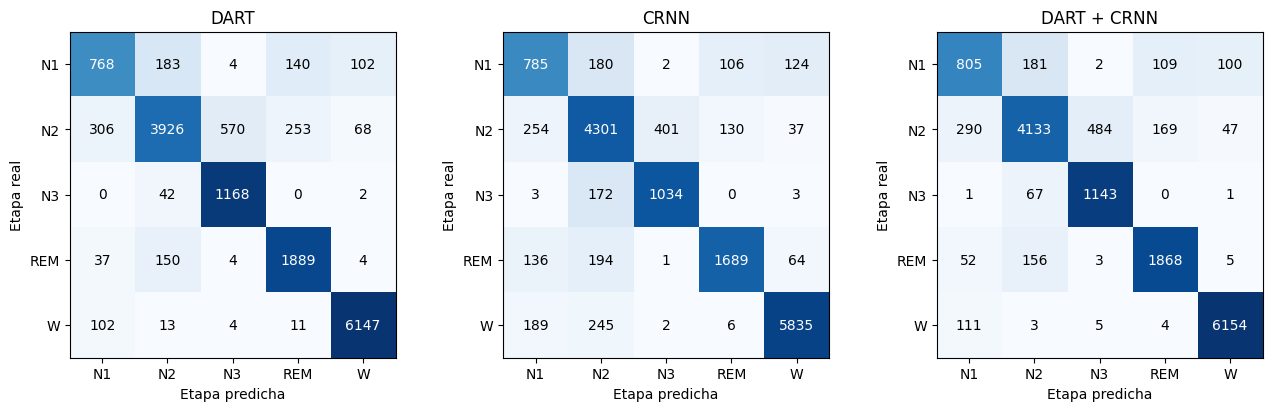

In [9]:
fig, axes = plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,m in zip(axes,modelos):
    cm = confusion_matrix(test.etapa,resultados[m],labels=CLASES)
    porcentajes = cm/cm.sum(axis=1,keepdims=True)
    ax.imshow(porcentajes,vmin=0,vmax=1,cmap='Blues')
    for (i,j),n in np.ndenumerate(cm):
        ax.text(j,i,str(n),ha='center',va='center',color='white' if porcentajes[i,j]>.55 else 'black')
    ax.set(xticks=range(5),xticklabels=CLASES,yticks=range(5),yticklabels=CLASES,
           title=m,xlabel='Etapa predicha',ylabel='Etapa real')
plt.show()

## Ajuste final con el 100 % y exportación

Se fijan las mismas dos arquitecturas y la mezcla 70/30. El ajuste final incorpora las noches que antes estuvieron en prueba. Las métricas anteriores corresponden exclusivamente a los pesos del ajuste 80/20. El manifiesto final se guarda en `data/models/dart_crnn_mixto/final_100/manifest.json`.

In [10]:
dart_final, crnn_final, ficha_final = ajustar_o_cargar('final_100',meta)
assert ficha_final['contrato']['segmentos_entrenamiento']==len(meta)
display(meta.groupby('cohorte').agg(personas=('subject_id','nunique'),noches=('record_id','nunique'),segmentos=('etapa','size')))
ejemplo = meta.iloc[:10]
rid = ejemplo.record_id.iloc[0]
assert ejemplo.record_id.nunique()==1
p = combinar(dart_final.predict(X.loc[ejemplo.index],num_threads=4),prob_crnn(crnn_final,entradas[rid])[ejemplo.epoch_index])
assert np.isfinite(p).all() and np.allclose(p.sum(1),1)
print('Pesos recargados y fusión verificada.')
print((STORE/'final_100/manifest.json').relative_to(ROOT).as_posix())

Ajustado y guardado: final_100 {'dart': 467.9, 'crnn': 37.2}


,personas,noches,segmentos
cohorte,,,
Cassette,12,12,32921
Telemetry,22,44,42691


Pesos recargados y fusión verificada.
data/models/dart_crnn_mixto/final_100/manifest.json


La verificaci?n de inferencia usa un PSG completo de Telemetry y devuelve una probabilidad por etapa y por segmento. El registro también formó parte del ajuste final. Esta salida verifica la recarga del modelo para inferencia.

In [11]:
def predecir_edf(archivo, cohorte, dart, crnn, ficha):
    contrato_modelo = ficha['contrato']
    perfil = contrato_modelo['preprocesamiento_dart'][cohorte]
    salida = PreprocessingPipeline(PreprocessingConfig(**perfil)).transform_edf(archivo)
    features = salida.features.reindex(columns=contrato_modelo['columnas_dart']).astype('float32')
    p_tab = dart.predict(features, num_threads=4)
    p_red = prob_crnn(crnn, entrada_crnn(archivo))
    probabilidades = combinar(p_tab, p_red)
    clases = np.array(contrato_modelo['clases'])
    tabla = pd.DataFrame(probabilidades, columns=['p_'+c for c in clases])
    return pd.concat([salida.metadata[['epoch_index','onset_seconds']].reset_index(drop=True),
                      tabla.assign(etapa=clases[probabilidades.argmax(axis=1)])], axis=1)

archivo = registros['Telemetry'][0].psg_path
predicciones = predecir_edf(archivo, 'Telemetry', dart_final, crnn_final, ficha_final)
np.testing.assert_allclose(predicciones.filter(regex='^p_').sum(axis=1), 1, atol=1e-6)
print(archivo.name, '·', len(predicciones), 'segmentos de 30 s')
display(predicciones.head(3).round(4))

ST7011J0-PSG.edf · 1196 segmentos de 30 s


,epoch_index,onset_seconds,p_N1,p_N2,p_N3,p_REM,p_W,etapa
0,0,0.0,0.0365,0.0110,0.0097,0.0120,0.9308,W
1,1,30.0,0.0118,0.0029,0.0042,0.0025,0.9787,W
2,2,60.0,0.0303,0.0029,0.0027,0.0020,0.9621,W
